In [62]:
import pandas as pd
import numpy as np
import string
import pickle

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC

from imblearn.over_sampling import SMOTE

In [ ]:
data = pd.read_csv('spam.csv', encoding='latin-1')
data.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
data.drop(['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], axis=1, inplace=True)
data.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
data.rename(columns={'v1': 'label', 'v2': 'text'}, inplace=True)
data.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [ ]:
le

LabelEncoder()

In [ ]:
data['Target'] = le.fit_transform(data['label'])
data.head()

,label,text,Target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [ ]:
data.isnull().sum()

,0
label,0
text,0
Target,0


In [ ]:
data.duplicated().sum()

np.int64(403)

In [ ]:
data = data.drop_duplicates(keep='first')
data.duplicated().sum()

np.int64(0)

In [ ]:
data.shape

(5169, 3)

In [ ]:
data['Target'].value_counts()

,count
Target,
0,4516
1,653


**#PLOTING**

Text(0.5, 1.0, 'Distribution of Ham and Spam Emails')

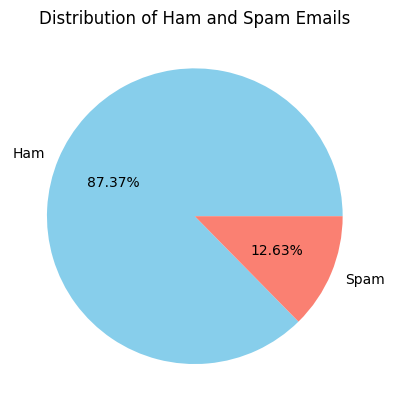

In [ ]:
plt.pie(data['Target'].value_counts(), labels=['Ham', 'Spam'], autopct='%0.2f%%', colors=['skyblue', 'salmon'])
plt.title('Distribution of Ham and Spam Emails')

In [ ]:
import nltk
nltk.download('punkt')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
data['Char_Count'] = data['text'].apply(len)
data.head()

,label,text,Target,Char_Count
0,ham,"Go until jurong point, crazy.. Available only ...",0,111
1,ham,Ok lar... Joking wif u oni...,0,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155
3,ham,U dun say so early hor... U c already then say...,0,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61


In [ ]:
import nltk
nltk.download('punkt_tab')
data['Words_Count'] = data['text'].apply(lambda x: len(nltk.word_tokenize(x)))

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
data.head()

,label,text,Target,Char_Count,words count
0,ham,"Go until jurong point, crazy.. Available only ...",0,111,24
1,ham,Ok lar... Joking wif u oni...,0,29,8
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,37
3,ham,U dun say so early hor... U c already then say...,0,49,13
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61,15


In [ ]:
data['Sentence_Count'] = data['text'].apply(lambda x: len(nltk.sent_tokenize(x)))
data.head()

,label,text,Target,Char_Count,words count,sentence count,Words_Count,Sentence_Count
0,ham,"Go until jurong point, crazy.. Available only ...",0,111,24,2,24,2
1,ham,Ok lar... Joking wif u oni...,0,29,8,2,8,2
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,37,2,37,2
3,ham,U dun say so early hor... U c already then say...,0,49,13,1,13,1
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61,15,1,15,1


In [ ]:
data[['Char_Count', 'Words_Count', 'Sentence_Count']].describe()

,Char_Count,Words_Count,Sentence_Count
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


**#PAIR PLOT**

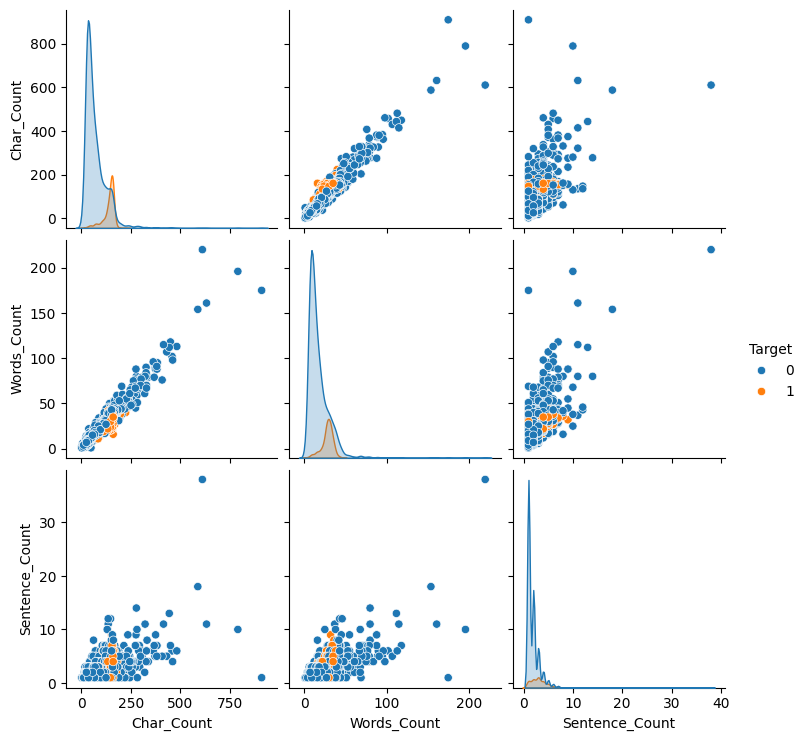

In [ ]:
sns.pairplot(data[['Char_Count', 'Words_Count', 'Sentence_Count', 'Target']], hue='Target')

In [50]:
import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

nltk.download('punkt')
nltk.download('stopwords')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [53]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
data['label'] = encoder.fit_transform(data['label'])

# Preprocessing
ps = PorterStemmer()


In [54]:
def preprocess(text):
    text = text.lower()
    tokens = nltk.word_tokenize(text)
    tokens = [i for i in tokens if i.isalnum()]
    tokens = [ps.stem(i) for i in tokens if i not in stopwords.words('english')]
    return " ".join(tokens)

data['processed_text'] = data['text'].apply(preprocess)

In [55]:
# Feature Engineering
def count_special(text):
    return sum(1 for char in text if char in '!@#$%^&*')

data['num_chars'] = data['text'].apply(len)
data['num_words'] = data['text'].apply(lambda x: len(x.split()))
data['num_special'] = data['text'].apply(count_special)

**Vectorization**

In [57]:
# Vectorization
tfidf = TfidfVectorizer(max_features=3000)
X_text = tfidf.fit_transform(data['processed_text']).toarray()

X_extra = data[['num_chars', 'num_words', 'num_special']].values
X = np.hstack((X_text, X_extra))
y = data['label'].values

In [58]:
# SMOTE
smote = SMOTE(random_state=42)
X, y = smote.fit_resample(X, y)

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [60]:
models = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(),
    'SVM': SVC(probability=True)
}

In [61]:
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"\n{name} Results:")
    print(classification_report(y_test, y_pred))


Naive Bayes Results:
              precision    recall  f1-score   support

           0       0.99      0.96      0.98       884
           1       0.96      0.99      0.98       923

    accuracy                           0.98      1807
   macro avg       0.98      0.98      0.98      1807
weighted avg       0.98      0.98      0.98      1807


Logistic Regression Results:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       884
           1       0.98      0.98      0.98       923

    accuracy                           0.98      1807
   macro avg       0.98      0.98      0.98      1807
weighted avg       0.98      0.98      0.98      1807


Random Forest Results:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       884
           1       1.00      0.99      0.99       923

    accuracy                           0.99      1807
   macro avg       0.99      0.99      0.99      180

**Ensembling**

In [63]:
voting = VotingClassifier(estimators=[
    ('lr', LogisticRegression(max_iter=1000)),
    ('nb', MultinomialNB()),
    ('rf', RandomForestClassifier())
], voting='soft')

voting.fit(X_train, y_train)
y_pred = voting.predict(X_test)

print("\nEnsemble Model Results:")
print(classification_report(y_test, y_pred))


Ensemble Model Results:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       884
           1       0.99      1.00      0.99       923

    accuracy                           0.99      1807
   macro avg       0.99      0.99      0.99      1807
weighted avg       0.99      0.99      0.99      1807



In [64]:
#Save Model
pickle.dump(tfidf, open('vectorizer.pkl', 'wb'))
pickle.dump(voting, open('spam_model.pkl', 'wb'))

**Prediction Function**

In [67]:
def predict_spam(text):
    processed = preprocess(text)
    vector = tfidf.transform([processed]).toarray()
    extra = np.array([[len(text), len(text.split()), count_special(text)]])
    final_input = np.hstack((vector, extra))
    result = voting.predict(final_input)[0]
    prob = voting.predict_proba(final_input)[0][1]
    return "Spam" if result == 1 else "Not Spam", prob

print(predict_spam("Congratulations! You won $1000 cash prize!"))
print(predict_spam("I live in Pakistan...!"))

('Spam', np.float64(0.752848234086355))
('Not Spam', np.float64(0.31434254133482115))
